In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import xgboost as xgb
import shap

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


/Users/dwr/code/recursive-leverage-defi/analysis/whale-risk-supervised/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('whale_features_labeled.csv', parse_dates=['date'])

print(f'Shape: {df.shape}')
print(f'Whales: {df["whale_id"].unique()}')

Shape: (667, 38)
Whales: <StringArray>
['W-1', 'W-2', 'W-3', 'W-4', 'W-5', 'W-6']
Length: 6, dtype: str


In [3]:
FEATURES = [
    'ltv',
    'ltv_lag_1',
    'ltv_lag_3',
    'ltv_lag_7',
    'ltv_vol_7d',
    'ltv_vol_14d',
    'carry_spread',
    'carry_spread_levered',
    'loop_depth',
]

TARGET = 'stressed_state'

print(f'Features: {len(FEATURES)}')
print(f'Target: {TARGET}')
print(f'\nTarget distribution:')
print(df[TARGET].value_counts())
print(f'\nStressed rate: {df[TARGET].mean():.1%}')

Features: 9
Target: stressed_state

Target distribution:
stressed_state
0    460
1    207
Name: count, dtype: int64

Stressed rate: 31.0%


**Target Distribution**

Out of 667 total days:
- **460 days** — whale was not stressed (0)
- **207 days** — whale was in a stressed state (1)
- **Overall stressed rate: 31.0%** — roughly 1 in 3 days across all whales was a stressed day

This is mildly imbalanced.

---

We predict `stressed_state` — whether a whale is in a stressed risk position on a given day (1 = stressed, 0 = not stressed).

**9 features are used:**

- `ltv`, `ltv_lag_1`, `ltv_lag_3`, `ltv_lag_7` — current and historical leverage ratio
- `ltv_vol_7d`, `ltv_vol_14d` — how volatile the leverage has been recently
- `carry_spread`, `carry_spread_levered` — yield earned minus borrow cost
- `loop_depth` — how many times the position is recursively looped

**Features excluded and why:**

- `health_factor`, `distance_to_liq` — these were used to **define** `stressed_state` so including them would let the model see the answer directly. This is called data leakage.
- `rebal_freq_7d`, `rebal_freq_30d`, `days_since_rebalance` — adding these worsened precision from 0.70 to 0.47 with only marginal ROC-AUC gain, so they were dropped for a cleaner model.
- `rebalancing` — this is a separate target variable, not a feature.

In [4]:
data = df.dropna(subset=FEATURES + [TARGET])

X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print(f'Train: {X_train.shape} | Stressed rate: {y_train.mean():.1%}')
print(f'Test:  {X_test.shape}  | Stressed rate: {y_test.mean():.1%}')

Train: (290, 9) | Stressed rate: 36.9%
Test:  (125, 9)  | Stressed rate: 36.8%


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

print('=== Logistic Regression (Baseline) ===')
print(classification_report(y_test, y_pred_lr))
print(f'ROC-AUC: {roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:,1]):.3f}')

y_pred_lr_tuned = (lr.predict_proba(X_test_scaled)[:,1] >= 0.3).astype(int)

print('=== Logistic Regression (threshold=0.3) ===')
print(classification_report(y_test, y_pred_lr_tuned))
print(f'ROC-AUC: {roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:,1]):.3f}')

=== Logistic Regression (Baseline) ===
              precision    recall  f1-score   support

           0       0.90      0.76      0.82        79
           1       0.67      0.85      0.75        46

    accuracy                           0.79       125
   macro avg       0.78      0.80      0.79       125
weighted avg       0.81      0.79      0.80       125

ROC-AUC: 0.849
=== Logistic Regression (threshold=0.3) ===
              precision    recall  f1-score   support

           0       0.97      0.37      0.53        79
           1       0.47      0.98      0.64        46

    accuracy                           0.59       125
   macro avg       0.72      0.67      0.59       125
weighted avg       0.79      0.59      0.57       125

ROC-AUC: 0.849


In [6]:
xgb_model = xgb.XGBClassifier(
    n_estimators=50,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    random_state=42,
    eval_metric='logloss',
    verbosity=0
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = (xgb_model.predict_proba(X_test)[:,1] >= 0.3).astype(int)

print('=== XGBoost (threshold=0.3) ===')
print(classification_report(y_test, y_pred_xgb))
print(f'ROC-AUC: {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:,1]):.3f}')

y_pred_xgb_default = xgb_model.predict(X_test)

print('=== XGBoost (threshold=0.5 default) ===')
print(classification_report(y_test, y_pred_xgb_default))
print(f'ROC-AUC: {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:,1]):.3f}')

=== XGBoost (threshold=0.3) ===
              precision    recall  f1-score   support

           0       0.96      0.85      0.90        79
           1       0.78      0.93      0.85        46

    accuracy                           0.88       125
   macro avg       0.87      0.89      0.88       125
weighted avg       0.89      0.88      0.88       125

ROC-AUC: 0.953
=== XGBoost (threshold=0.5 default) ===
              precision    recall  f1-score   support

           0       0.85      0.99      0.91        79
           1       0.97      0.70      0.81        46

    accuracy                           0.88       125
   macro avg       0.91      0.84      0.86       125
weighted avg       0.89      0.88      0.87       125

ROC-AUC: 0.953


## Model Comparison — Stressed State Prediction

We tested two models (Logistic Regression and XGBoost) at two decision thresholds (0.5 default and 0.3) to find the best approach for predicting stressed risk states.

| Model | Threshold | Recall | Precision | ROC-AUC | Accuracy |
|---|---|---|---|---|---|
| Logistic Regression | 0.5 | 0.85 | 0.67 | 0.849 | 79% |
| Logistic Regression | 0.3 | 0.98 | 0.47 | 0.849 | 59% |
| XGBoost | 0.5 | 0.70 | 0.97 | 0.953 | 88% |
| XGBoost | 0.3 | **0.93** | **0.78** | **0.953** | **88%** |

### Why threshold 0.3?

By default a model predicts stressed only when it is more than 50% confident.
Lowering to 0.3 means the model raises an alarm when it is 30% confident — catching more stressed days at the cost of some false alarms.

In a risk management context **missing a stressed day is far more costly than a false alarm** — a missed stressed day could mean a whale gets liquidated. So lowering the threshold is a deliberate and justified decision.

### Why XGBoost at threshold 0.3?

- **Recall 0.93** — catches 93% of stressed days, missing very few events
- **Precision 0.78** — when it predicts stress it is correct 78% of the time
- **ROC-AUC 0.953** — strong ability to distinguish stressed from non-stressed days
- **Accuracy 88%** — highest overall accuracy alongside the default threshold variant

Logistic Regression at threshold 0.3 also achieves high recall (0.98) but precision drops to 0.47 — meaning more than half of stress predictions are false alarms. XGBoost at 0.3 strikes the better balance: nearly as sensitive, but far more precise.

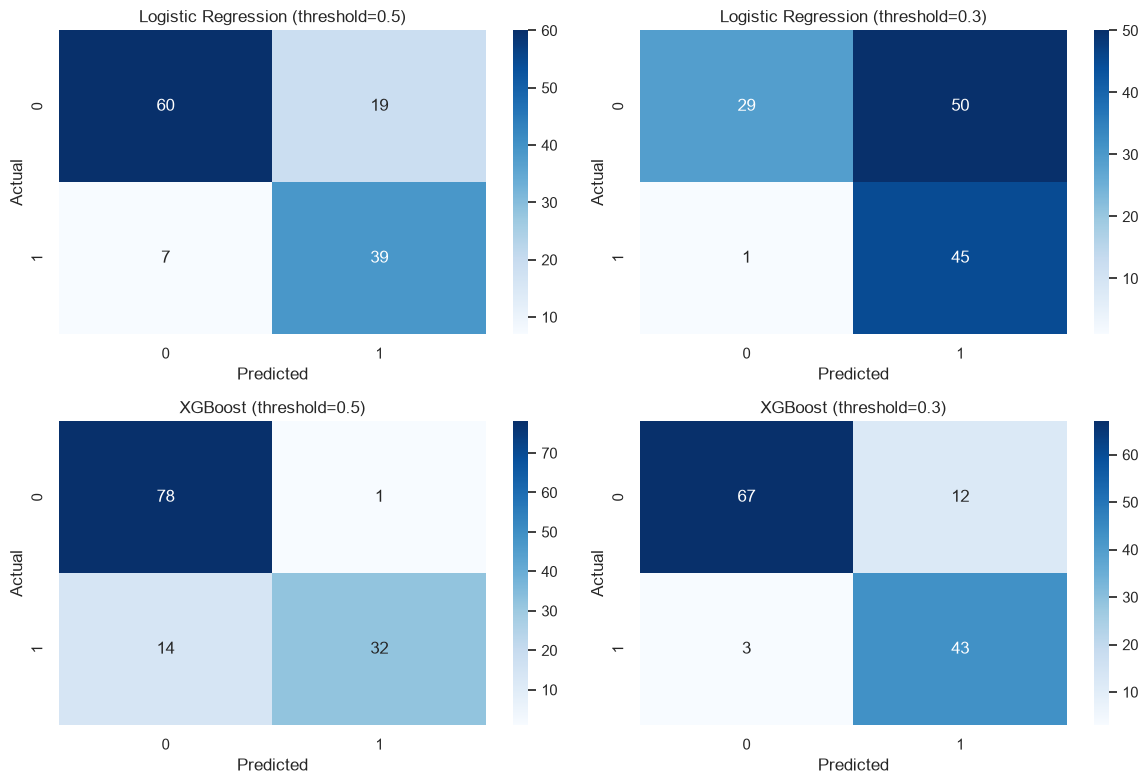

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

variants = [
    (y_pred_lr, 'Logistic Regression (threshold=0.5)'),
    (y_pred_lr_tuned, 'Logistic Regression (threshold=0.3)'),
    (y_pred_xgb_default, 'XGBoost (threshold=0.5)'),
    (y_pred_xgb, 'XGBoost (threshold=0.3)'),
]

for ax, (preds, title) in zip(axes.flatten(), variants):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

## Confusion Matrices — Stressed State Model

Each matrix shows how well the model predicts stressed days (1) vs non-stressed days (0).

- **Top left** = correctly predicted not stressed
- **Top right** = predicted stressed but was wrong (false alarm)
- **Bottom left** = missed actual stressed days (dangerous)
- **Bottom right** = correctly predicted stressed

---

### Logistic Regression (threshold=0.5)
- Caught 39 out of 46 stressed days — missed 7
- Made 19 false alarms out of 79 non-stressed days
- Misses 1 in 6 stressed days — decent but not reliable enough for risk management

### Logistic Regression (threshold=0.3)
- Caught 45 out of 46 stressed days — missed only 1
- But made 50 false alarms out of 79 non-stressed days — most non-stressed days incorrectly flagged
- Near-perfect recall but too many false alarms to be practical

### XGBoost (threshold=0.5)
- Caught only 32 out of 46 stressed days — missed 14
- Very few false alarms (only 1 out of 79)
- Too conservative — misses 30% of stressed days despite high precision

### XGBoost (threshold=0.3) — Best model
- Caught 43 out of 46 stressed days — missed only 3
- Only 12 false alarms out of 79 non-stressed days
- Best tradeoff: high recall with manageable false alarms

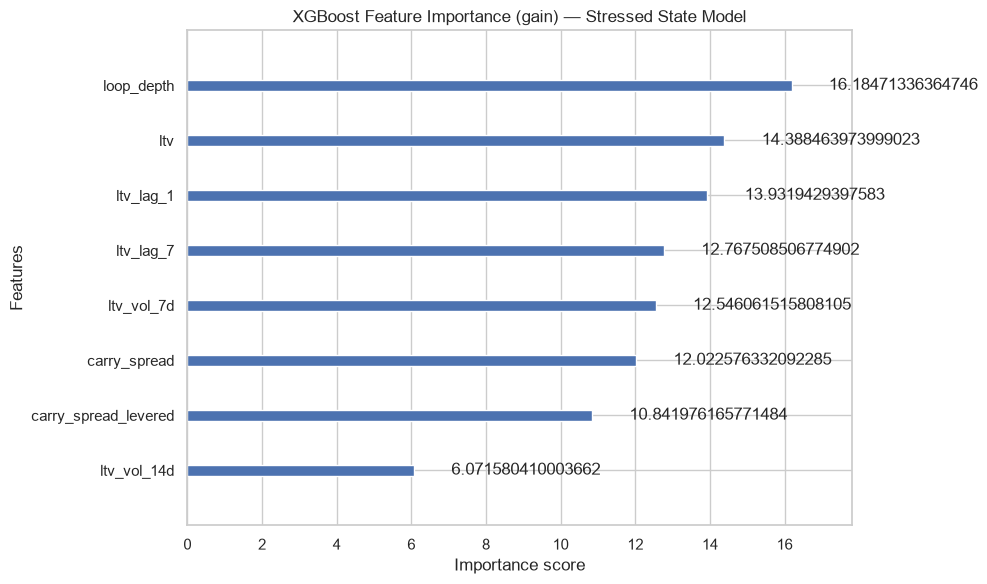

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
xgb.plot_importance(xgb_model, ax=ax, max_num_features=12, importance_type='gain')
ax.set_title('XGBoost Feature Importance (gain) — Stressed State Model')
plt.tight_layout()
plt.show()

## XGBoost Feature Importance — Stressed State Model

This chart shows which features the model relied on most to predict stressed states.
Higher score = more useful for making predictions.

### Top features:

- **`loop_depth` (16.2)** — the strongest predictor of stress. How deeply looped a
  position is drives stressed states more than any other single signal.
- **`ltv` (14.4)** — current LTV is the second most important. Stress is an
  instantaneous state — where you are right now matters greatly.
- **`ltv_lag_1` (13.9)** — yesterday's LTV is nearly as important as today's.
  If leverage was high yesterday it is very likely still high or higher today.
- **`ltv_lag_7` (12.8)** — LTV from 7 days ago still contributes — sustained high
  leverage over a week is a strong stress signal.
- **`ltv_vol_7d` (12.5)** — volatile leverage over the past week signals stress.
  Unstable positions are more likely to be in a stressed state.
- **`carry_spread` (12.0)** — yield spread has meaningful influence here, unlike
  in the rebalancing model.
- **`carry_spread_levered` (10.8)** — when yield compresses relative to borrow cost,
  the position becomes less profitable and more stressed.

### Bottom features:

- **`ltv_vol_14d` (6.1)** — longer-term volatility is the least important feature.
  Recent and current leverage levels matter far more than longer-term volatility patterns.

### Key difference from the Rebalancing Model:

| | Rebalancing Model | Stressed State Model |
|---|---|---|
| Top feature | `ltv_lag_7` | `loop_depth` |
| Current `ltv` rank | 9th | 2nd |
| `carry_spread` rank | Last | 6th |

Stressed states are driven by **position structure and current leverage** — loop depth
and present LTV dominate. Rebalancing is driven by **leverage buildup over time** — a
delayed behavioural response. Yield compression matters for stress but not for
rebalancing — whales rebalance for risk reasons, not yield reasons.

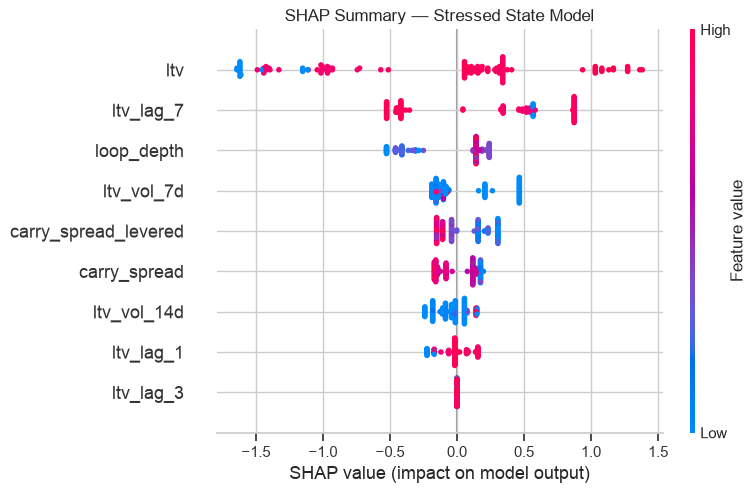

In [11]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, feature_names=FEATURES, show=False)
plt.title('SHAP Summary — Stressed State Model')
plt.tight_layout()
plt.show()

## SHAP Summary — Stressed State Model

Each dot is one day in the test set. Position on the x-axis shows how much that
feature pushed the prediction toward stressed (right) or away from it (left).
Color shows the feature value — pink = high, blue = low.

### Reading each feature:

**`ltv` — top feature, clearest and widest pattern**
- Pink dots far right → high LTV strongly predicts stressed state
- Blue dots far left → low LTV strongly reduces stress prediction
- Widest x-axis spread of any feature, ranging from -1.5 to +1.5
- The most direct signal — high leverage today means stressed today

**`ltv_lag_7` — second**
- Pink dots right → high LTV 7 days ago predicts stress today
- Blue dots cluster left — low historical LTV reduces stress prediction
- Notably, some blue dots appear on the right — a complex relationship where
  occasionally low old LTV still associates with stress

**`loop_depth` — third**
- Blue dots left → low loop depth reduces stress prediction
- Pink dots right → high loop depth pushes toward stress
- Deeper looping strategies are more likely to enter stressed states

**`ltv_vol_7d`**
- Dots cluster near zero with slight rightward spread
- Both colors present — short-term volatility has a modest and mixed effect on stress

**`carry_spread_levered`**
- Pink dots cluster slightly left — high levered yield spread mildly reduces stress
- Blue dots near zero or slightly right — low spread nudges toward stress
- Yield compression is a mild stress contributor

**`carry_spread`, `ltv_vol_14d`, `ltv_lag_1`, `ltv_lag_3`**
- All tightly clustered near zero — minimal influence on predictions

### Key thesis finding:

Stressed states are driven by **high current LTV and loop depth** — present-moment
signals dominate. Unlike the rebalancing model where `ltv_lag_7` drove predictions
through accumulated history, here today's leverage level and position structure are
primary. Yield compression (`carry_spread_levered`) has a mild secondary effect —
when levered yield is good the position is less likely to be stressed.

In [10]:
results = data.loc[X_test.index].copy()
results['pred_stressed'] = y_pred_xgb
results['pred_proba_stressed'] = xgb_model.predict_proba(X_test)[:,1]
results[['whale_id', 'date', 'stressed_state', 'pred_stressed', 'pred_proba_stressed']].to_csv('predictions_stressed.csv', index=False)
print('Saved: predictions_stressed.csv')

Saved: predictions_stressed.csv
